> **Experiment F3: FedProx mu sweep**
> Guide: [F3 FedProx sweep](../docs/experiments/F3_fedprox_sweep.md) · Config: [fed_fedprox.yaml](../configs/fed_fedprox.yaml)
> Depends on the validated E03 client dataset, F1's federated code and the corrected Arm D baseline.

# How strongly should clients be held to the global model?
FedProx adds (mu/2)·‖w − w_global‖² to every client's loss. **One Kaggle session runs one mu**: set `WT_F3_MU` to a value from `mu_grid` in the config (0, 0.001, 0.01, 0.1, 1, 10). Each session is 100 rounds × 2 local epochs over all retained rows, about the cost of a full F1 run. Run mu = 0 first: it is FedAvg at two local epochs and anchors the curve.

When several sessions have finished, attach their outputs and run section 8 to build `care_vs_mu.csv` and the curve. `WT_F3_ROUNDS` makes an explicit pilot; `WT_F3_SMOKE=1` runs a synthetic two-round CPU check. No stored outputs are included.

## 1. Load the exact shared source
Same loader as F1: local checkout, the attached `windturbine-client-bridge.zip`, or an explicit published git revision. `WT_REPO_ROOT` and `WT_REPO_REF` are mutually exclusive, and bundle files are checked against their manifest before any import.

In [1]:
import os, sys, json, zipfile, subprocess, hashlib
from pathlib import Path
from dataclasses import replace
import numpy as np
import pandas as pd

os.environ.setdefault("FLWR_TELEMETRY_ENABLED", "0")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
SMOKE = os.environ.get("WT_F3_SMOKE", "0") == "1"
if SMOKE:
    # Small deterministic CPU smoke avoids consuming GPU resources.
    os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
    os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
    os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
WORK_ROOT = Path(os.environ.get("WT_WORK_ROOT", "/kaggle/working" if Path("/kaggle/input").exists() else str(Path.cwd())))
WORK_ROOT.mkdir(parents=True, exist_ok=True)
MODULE = Path("src/windturbine/federated/strategies.py")
explicit_root, requested_ref = os.environ.get("WT_REPO_ROOT"), os.environ.get("WT_REPO_REF")
if explicit_root and requested_ref:
    raise ValueError("Choose WT_REPO_ROOT or WT_REPO_REF, not both")
REPO, bundle_sha256, resolved_ref = None, None, None
if explicit_root:
    REPO = Path(explicit_root)
    if not (REPO / MODULE).is_file():
        raise RuntimeError("WT_REPO_ROOT does not contain the client bridge: " + str(REPO))
elif requested_ref:
    REPO = WORK_ROOT / "windturbine-client-bridge-git"
    if not REPO.exists():
        subprocess.run(["git", "clone", "https://github.com/PranavMundhra/Wind-Turbine.git", str(REPO)], check=True)
    subprocess.run(["git", "-C", str(REPO), "checkout", "--detach", requested_ref], check=True)
    resolved_ref = subprocess.run(["git", "-C", str(REPO), "rev-parse", "HEAD"], check=True, capture_output=True, text=True).stdout.strip()
    expected_ref = subprocess.run(["git", "-C", str(REPO), "rev-parse", requested_ref + "^{commit}"], check=True, capture_output=True, text=True).stdout.strip()
    assert resolved_ref == expected_ref, "Requested source revision was not selected"
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    if Path("/kaggle/input").exists():
        candidates += [p.parent.parent.parent.parent for p in Path("/kaggle/input").rglob("src/windturbine/federated/strategies.py")]
    REPO = next((p for p in candidates if (p / MODULE).is_file()), None)
    if REPO is None and Path("/kaggle/input").exists():
        bundles = list(Path("/kaggle/input").rglob("windturbine-client-bridge.zip"))
        if len(bundles) > 1:
            raise RuntimeError("Attach only one source ZIP, or set WT_REPO_ROOT")
        if bundles:
            bundle_sha256 = hashlib.sha256(bundles[0].read_bytes()).hexdigest()
            target = WORK_ROOT / ("windturbine-source-" + bundle_sha256[:16])
            with zipfile.ZipFile(bundles[0]) as archive:
                names = archive.namelist()
                if len(names) != len(set(names)):
                    raise ValueError("Duplicate paths in source archive")
                for name in names:
                    if "\\" in name or not (target / name).resolve().is_relative_to(target.resolve()):
                        raise ValueError("Unsafe source archive path")
                package_manifest = json.loads(archive.read("bridge_bundle_manifest.json"))
                if package_manifest.get("format_version") != 1 or not isinstance(package_manifest.get("files"), dict):
                    raise ValueError("Unsupported source bundle manifest")
                files = package_manifest["files"]
                if set(names) != set(files) | {"bridge_bundle_manifest.json"}:
                    raise ValueError("Source bundle file list does not match manifest")
                for name, digest in files.items():
                    if hashlib.sha256(archive.read(name)).hexdigest() != digest:
                        raise ValueError("Source bundle hash mismatch: " + name)
                archive.extractall(target)
            REPO = target
if REPO is None or not (REPO / MODULE).is_file():
    raise RuntimeError("Attach windturbine-client-bridge.zip as a Kaggle Dataset (internet off works), "
                       "or attach a source checkout and set WT_REPO_ROOT. Optional internet mode: "
                       "set WT_REPO_REF to a published commit/tag containing src/windturbine/federated/strategies.py.")
# Also verify an already extracted source bundle before importing any package code.
if (REPO / "bridge_bundle_manifest.json").is_file():
    package_manifest = json.loads((REPO / "bridge_bundle_manifest.json").read_text(encoding="utf-8"))
    if package_manifest.get("format_version") != 1:
        raise ValueError("Unsupported extracted source bundle")
    for name, digest in package_manifest["files"].items():
        source_path = (REPO / name).resolve()
        if not source_path.is_relative_to(REPO.resolve()) or hashlib.sha256(source_path.read_bytes()).hexdigest() != digest:
            raise ValueError("Extracted source bundle hash mismatch: " + name)
source_notebooks = [REPO / "notebooks" / name for name in ("13_arm_local_turbine.ipynb", "20_federated_clients.ipynb", "30_fedavg.ipynb",
                                                    "31_fed_personalised.ipynb", "32_fedprox.ipynb", "33_fed_private.ipynb")]
source_files = sorted([*REPO.glob("src/windturbine/**/*.py"), *REPO.glob("configs/*.yaml"),
                       *(p for p in source_notebooks if p.is_file())])
source_hashes = {p.relative_to(REPO).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
SOURCE_IDENTITY = {"source_tree_sha256": hashlib.sha256(json.dumps(source_hashes, sort_keys=True).encode()).hexdigest(),
                   "source_files": source_hashes, "bundle_sha256": bundle_sha256,
                   "requested_git_ref": requested_ref, "resolved_git_commit": resolved_ref}
sys.path.insert(0, str(REPO / "src"))
from windturbine.config import load_config
print("Source:", REPO)
print("Source identity:", json.dumps(SOURCE_IDENTITY, indent=2))

Source: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine
Source identity: {
  "source_tree_sha256": "4cde0e5f61abdad622ca441316b667590511bd69365a5b480164cc2963bcea0a",
  "source_files": {
    "configs/arm_isolated.yaml": "ab352789a22a1d3cfe52d6854ebe095a04e85be89b10e0d51beedd3694ec8af1",
    "configs/arm_local_turbine.yaml": "8db53eded3df967c36e65c4a4d3712438a24581bc2a3abb6fb74520a59261795",
    "configs/arm_pooled.yaml": "c2c70de648928f873760115a5f405f3abb44ca6fe663cb9ee7054cb79c69cfb7",
    "configs/arm_pooled_dedup.yaml": "485e5470df67831de28dde349d7874554857f9cf9b4d0b7ccba1ba717f40b34d",
    "configs/base.yaml": "16668bbdc1a309e8c60d5c8fcc7d831bed2b7fb5b72eb28cfbb19d461a6e7533",
    "configs/clients.yaml": "41cdfee241855f0eb93d228d471b9a8c1224214155b539a25e96e5f0b1121f52",
    "configs/fed_fedavg.yaml": "d538f349350da04a4addcca612adcca1e3fb4e90fec9e699eee1c6a35a1f5be9",
    "configs/fed_fedprox.yaml": "c747ea630eac78e088756a5a736a611ad152153d3544d37d5b7c5954d4a0e57b",
    "configs/

## 2. Check training dependencies
Flower 1.40.0 is the tested aggregation version and TensorFlow 2.21.0 the local validation version. The notebook does not install packages; see the F1 notebook for Kaggle install options. Restart the kernel after changing binary packages.

In [2]:
from importlib import metadata
missing = []
for package in ('flwr', 'tensorflow'):
    try:
        print(package, metadata.version(package))
    except metadata.PackageNotFoundError:
        missing.append(package)
if missing:
    raise RuntimeError("Missing training packages: " + ", ".join(missing) +
                       ". Follow the setup instructions above; this notebook does not install packages automatically.")
if metadata.version("flwr") != "1.40.0":
    raise RuntimeError("Use the tested flwr==1.40.0 aggregation API; restart the kernel after installing it.")
try:
    import tensorflow as tf
    from windturbine.federated import (build_synthetic_clients, load_checkpoint, run_federated, run_preflight,
                                       run_strategy_preflight, summarize_runs)
except ImportError as exc:
    raise RuntimeError("Training dependencies or shared F2-F4 source are unavailable. Attach the updated source bundle.") from exc
print("TensorFlow devices:", tf.config.list_physical_devices())

flwr 1.40.0
tensorflow 2.21.0


TensorFlow devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 3. Resolve the experiment, mu and saved client dataset
`WT_F3_MU` is required outside the smoke run; values off the starting grid are allowed for refinement and are recorded. mu is part of the output folder name so sessions never collide.

In [3]:
from datetime import datetime, timezone

CFG = load_config(REPO / "configs/base.yaml", REPO / "configs/fed_fedprox.yaml")
CFG = replace(CFG, seed=int(os.environ.get("WT_SEED", CFG.seed)))
mu_text = os.environ.get("WT_F3_MU", "0.1" if SMOKE else "")
if not mu_text:
    raise RuntimeError("Set WT_F3_MU to one value from mu_grid " + str(CFG.extra["mu_grid"]) + "; run 0 first")
MU = float(mu_text)
if MU not in CFG.extra["mu_grid"]:
    print("Note: mu", MU, "is off the starting grid (refinement run)")
CFG = replace(CFG, extra={**CFG.extra, "mu": MU})

if os.environ.get("WT_F3_ROUNDS"):
    rounds = int(os.environ["WT_F3_ROUNDS"])
    if rounds < 1:
        raise ValueError("WT_F3_ROUNDS must be positive")
    CFG = replace(CFG, extra={**CFG.extra, "rounds": rounds})
if SMOKE:
    # Synthetic data exists only to exercise the full export/training/readback path.
    CLIENT_ROOT, smoke_fields, smoke_extra = build_synthetic_clients(
        WORK_ROOT / "f3_smoke", REPO / "configs", farm=CFG.farm, source_identity=SOURCE_IDENTITY)
    CFG = replace(CFG, **smoke_fields, extra={**CFG.extra, **smoke_extra})
else:
    if os.environ.get("WT_CLIENT_DATASET"):
        CLIENT_ROOT = Path(os.environ["WT_CLIENT_DATASET"])
    else:
        candidates = list(Path("/kaggle/input").rglob("dataset_manifest.json")) if Path("/kaggle/input").exists() else []
        if len(candidates) != 1:
            raise RuntimeError("Attach the E03 output and set WT_CLIENT_DATASET to its folder containing dataset_manifest.json")
        CLIENT_ROOT = candidates[0].parent

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_ROOT = Path(os.environ.get("WT_F3_OUTPUT_ROOT", str(WORK_ROOT / CFG.output_dir / "F3" / (f"mu_{MU:g}_" + stamp))))
if Path("/kaggle/input").exists() and not OUTPUT_ROOT.resolve().is_relative_to(Path("/kaggle/working").resolve()):
    raise ValueError("WT_F3_OUTPUT_ROOT must be inside /kaggle/working on Kaggle")
print("Mode:", "SYNTHETIC SMOKE" if SMOKE else "PILOT" if CFG.extra["rounds"] < 100 else "FULL")
print("Saved clients:", CLIENT_ROOT)
print("Run output:", OUTPUT_ROOT)
print("Resolved config:", CFG)

Mode: FULL
Saved clients: D:\wt_work\windturbine_clients
Run output: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine\results\runs\F3\mu_0.01_20261026T205303_936568Z
Resolved config: Config(farm='Wind Farm C', dataset_root='data/raw', cache_dir='data/cache', use_avg_only=True, drop_reactive=False, angle_transform=True, max_nan_fraction=0.3, normal_status_ids=(0, 2), wind_speed_cutin=3.0, wind_speed_rated=12.0, power_near_zero_thresh=0.02, hidden_layers=(133, 83, 20, 83, 133), learning_rate=0.0056, use_lr_plateau=False, lr_plateau_factor=0.5, lr_plateau_patience=4, noise_std=0.0, batch_size=64, max_epochs=200, early_stop_patience=10, seed=42, val_fraction=0.15, val_split_mode='blocked', val_block_hours=120, score_quantile=0.99, criticality_threshold=72, beta=0.5, care_weights=(1, 1, 1, 2), arm='fedprox', output_dir='results/runs', extra={'framework': 'flwr', 'strategy': 'fedprox', 'mu_grid': [0.0, 0.001, 0.01, 0.1, 1.0, 10.0], 'n_clients': 22, 'expected_clients': 22, 'expected_events': 

## 4. Pass the algorithm and scoring gates
F1's gates (Flower aggregation equals full-batch SGD on unequal clients, server CARE equals direct CARE, TensorFlow checkpoint round trip) run first. The F2-F4 gates then check that secure aggregation equals the row-weighted mean, FedProx with mu=0 equals plain training, DP-SGD with no noise and no effective clipping equals plain training, and the proximal term pulls weights toward the anchor. The run repeats both before training; failure stops it.

In [4]:
preflight = {"fedavg": run_preflight(), "strategy": run_strategy_preflight()}
assert preflight["fedavg"]["passed"] and preflight["strategy"]["passed"], "Preflight gates did not pass"
print(json.dumps(preflight, indent=2, default=str))

W1027 02:23:05.470000 29156 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


{
  "fedavg": {
    "passed": true,
    "sgd_equivalence": {
      "passed": true,
      "rounds": 3,
      "client_rows": [
        3,
        5,
        8
      ],
      "parameter_arrays": 2,
      "max_abs_error": 5.551115123125783e-17,
      "tolerance": 1e-12
    },
    "care_parity": {
      "passed": true,
      "events": 3,
      "results": {
        "Coverage": 1.0,
        "Earliness": 1.0,
        "Reliability": 1.0,
        "Accuracy": 1.0,
        "CARE": 1.0,
        "support": {
          "coverage": 1,
          "earliness": 1,
          "accuracy": 2
        },
        "event_confusion": {
          "tp": 1,
          "fp": 0,
          "fn": 0,
          "tn": 2
        },
        "n_anomaly_events": 1,
        "n_normal_events": 2
      }
    },
    "tensorflow_compatibility": {
      "passed": true,
      "clients": 3,
      "validation_mse": 0.3141769187054198,
      "checkpoint_roundtrip": true,
      "keras_backend": "torch 2.11.0+cu128"
    }
  },
  "strategy":

## 5. Run FedProx for this mu
Each client minimises its reconstruction loss plus (mu/2)·‖w − w_broadcast‖² for two local epochs, then Flower averages all weights by retained training rows. With mu = 0 this is exactly FedAvg at two local epochs (tested bit-for-bit), the sweep's own baseline. Selection, scoring and the runtime guard are as in F2.

In [5]:
run_manifest = run_federated(CLIENT_ROOT, OUTPUT_ROOT, CFG, experiment="F3", source_identity=SOURCE_IDENTITY)
(BRANCH, BRANCH_INFO), = run_manifest["branches"].items()
print("Completed branch:", BRANCH, "selected round", BRANCH_INFO["selected_epoch"])

fedprox round 1/100: validation MSE 0.905268 (73.0s)
Projected total runtime: 2.28 h (limit 11 h)


fedprox round 2/100: validation MSE 0.512333 (69.5s)
Projected total runtime: 2.28 h (limit 11 h)


fedprox round 3/100: validation MSE 0.484732 (70.4s)
Projected total runtime: 2.28 h (limit 11 h)


fedprox round 4/100: validation MSE 0.439069 (69.6s)


fedprox round 5/100: validation MSE 0.441188 (58.4s)


...

fedprox round 97/100: validation MSE 0.330648 (69.2s)


fedprox round 98/100: validation MSE 0.322631 (69.7s)


fedprox round 99/100: validation MSE 0.313791 (69.8s)


fedprox round 100/100: validation MSE 0.322024 (69.9s)


Completed branch: fedprox selected round 94


## 6. Verify the saved run and reload checkpoints
Do not trust an interrupted export: check the completion marker and every artifact hash before reading results. Each turbine's selected model is reloaded from `selected/client_<id>.npz`.

In [6]:
print("Run artifacts:", OUTPUT_ROOT)
for relative, expected_hash in run_manifest["artifacts"].items():
    artifact = (OUTPUT_ROOT / relative).resolve()
    assert artifact.is_relative_to(OUTPUT_ROOT.resolve()), "Unsafe artifact path"
    assert hashlib.sha256(artifact.read_bytes()).hexdigest() == expected_hash, relative
assert (OUTPUT_ROOT / "COMPLETE").is_file(), "Run was not completely published"
selected = {aid: load_checkpoint(OUTPUT_ROOT / BRANCH_INFO["checkpoint"] / f"client_{aid}.npz")
            for aid in run_manifest["clients"]}
assert all(weights and all(np.isfinite(w).all() for w in weights) for weights in selected.values())
shared = set(run_manifest["shared_parameter_indices"])
first = next(iter(selected.values()))
for index in range(len(first)):
    identical = all(np.array_equal(weights[index], first[index]) for weights in selected.values())
    assert identical == (index in shared or len(selected) == 1), f"Parameter {index} sharing is wrong"
print("Reloaded", len(selected), "client models;", len(shared), "of", len(first), "parameter arrays are shared")

Run artifacts: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine\results\runs\F3\mu_0.01_20261026T205303_936568Z


Reloaded 22 client models; 12 of 12 parameter arrays are shared


## 7. Read this mu's result
One mu is one point on the curve. Compare it with mu = 0 (FedAvg at the same budget), D, and optionally F1 (`WT_F1_RUN`). A nonzero mu that beats mu = 0 means the proximal constraint helps under these settings; no improvement anywhere on the grid is a measured null, not proof that collaboration fails.

D reference is not comparable to this dataset; no D improvement claim is valid.
        method  selected_round     CARE  Coverage  Earliness  Reliability  Accuracy
    F3 fedprox              94 0.636157  0.350939   0.309287     0.654206  0.933177
F1 centralized               2 0.640495  0.316136   0.243760     0.722892  0.959842
     F1 fedavg              26 0.636185  0.352729   0.294210     0.654206  0.939891
 epoch  validation_mse
     0        1.141396
     1        0.905268
     2        0.512333
     3        0.484732
     4        0.439069
     5        0.441188
     6        0.421723
     7        0.411169
     8        0.399366
     9        0.494288
    10        0.406437
    11        0.393363
    12        0.383240
    13        0.378392
    14        0.429323
    15        0.369736
    16        0.391015
    17        0.372617
    18        0.366102
    19        0.365870
    20        0.377016
    21        0.422258
    22        0.403234
    23        0.362547
    24   

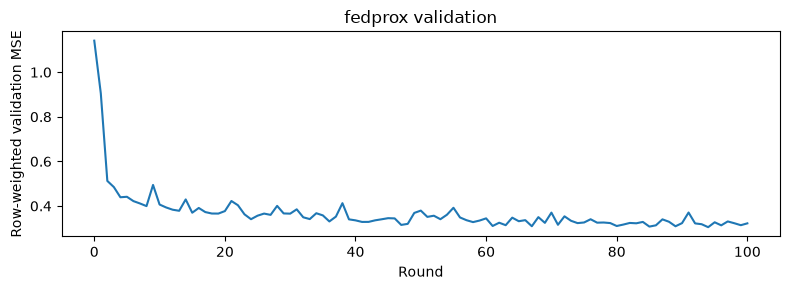

Keep the entire run folder for review: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine\results\runs\F3\mu_0.01_20261026T205303_936568Z


In [7]:
reference_hash = "bb2ed3ffc84adbf79bbba624941090acd91831097f427b38b2e20885d4b0b1d1"
dataset_hash = hashlib.sha256((CLIENT_ROOT / "dataset_manifest.json").read_bytes()).hexdigest()
metrics = ["CARE", "Coverage", "Earliness", "Reliability", "Accuracy"]
rows = [{"method": "F3 " + BRANCH, "selected_round": BRANCH_INFO["selected_epoch"],
         **{key: BRANCH_INFO["results"][key] for key in metrics}}]
# Optional: point WT_F1_RUN at an attached, completed F1 run folder to compare on the same table.
if os.environ.get("WT_F1_RUN"):
    f1 = summarize_runs([Path(os.environ["WT_F1_RUN"])])
    if f1.dataset_manifest_sha256.iloc[0] != dataset_hash:
        raise ValueError("WT_F1_RUN used a different dataset")
    rows += [{"method": "F1 " + row.branch, "selected_round": row.selected_epoch,
              **{key: getattr(row, key) for key in metrics}} for row in f1.itertuples()]
comparison = pd.DataFrame(rows)
if dataset_hash == reference_hash and not SMOKE:
    comparison = pd.concat([comparison, pd.DataFrame([{"method": "D (accepted seed 42)", "CARE": 0.639852}])],
                           ignore_index=True)
    print("Matched D dataset; D CARE 0.639852 is a valid single-seed reference.")
else:
    print("D reference is not comparable to this dataset; no D improvement claim is valid.")
print(comparison.to_string(index=False))
curve = pd.read_csv(OUTPUT_ROOT / BRANCH_INFO["rounds"])
print(curve[["epoch", "validation_mse"]].to_string(index=False))
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Install matplotlib for an inline curve; the full values are shown above.")
else:
    ax = curve.plot(x="epoch", y="validation_mse", title=BRANCH + " validation", figsize=(8, 3), legend=False)
    ax.set_xlabel("Round")
    ax.set_ylabel("Row-weighted validation MSE")
    plt.tight_layout()
    plt.show()
print("Keep the entire run folder for review:", OUTPUT_ROOT)

## 8. Collect the sweep across sessions
Each Kaggle session runs one mu value. Save every finished session's output (*Save Version*, then add it as a dataset) and attach them all to one session. This cell finds every completed F3 run under `/kaggle/input` (or the folders listed in `WT_F3_SWEEP`, separated by `:` on Kaggle/Linux), verifies their hashes, and writes `care_vs_mu.csv`. Runs on different datasets are rejected. Rows from a single seed are exploratory.

                            run   mu     CARE  Coverage  Earliness  Reliability  Accuracy  selected_epoch
mu_0.01_20261026T205303_936568Z 0.01 0.636157  0.350939   0.309287     0.654206  0.933177              94
Saved C:\Users\pooja\Desktop\wind turbine\Wind-Turbine\results\runs\F3\care_vs_mu.csv


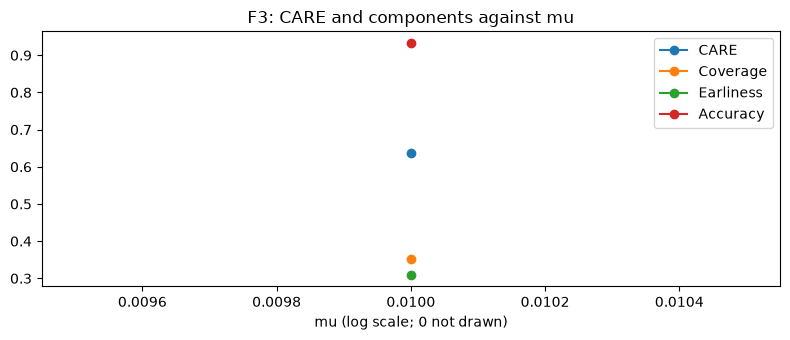

In [8]:
if os.environ.get("WT_F3_SWEEP"):
    sweep_dirs = [Path(p) for p in os.environ["WT_F3_SWEEP"].split(os.pathsep) if p]
else:
    found = list(Path("/kaggle/input").rglob("manifest.json")) if Path("/kaggle/input").exists() else []
    sweep_dirs = [p.parent for p in found if (p.parent / "COMPLETE").is_file()
                  and json.loads(p.read_text(encoding="utf-8")).get("experiment") == "F3"]
sweep_dirs = sorted({p.resolve() for p in sweep_dirs} | {OUTPUT_ROOT.resolve()})
sweep = summarize_runs(sweep_dirs).sort_values("mu").reset_index(drop=True)
sweep_path = OUTPUT_ROOT.parent / "care_vs_mu.csv"
sweep.to_csv(sweep_path, index=False)
print(sweep[["run", "mu", "CARE", "Coverage", "Earliness", "Reliability", "Accuracy", "selected_epoch"]].to_string(index=False))
print("Saved", sweep_path)
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Install matplotlib for the curve; the table above has every value.")
else:
    finite = sweep[np.isfinite(sweep["mu"])]
    ax = finite.plot(x="mu", y=["CARE", "Coverage", "Earliness", "Accuracy"], marker="o", figsize=(8, 3.5),
                     title="F3: CARE and components against mu")
    if (finite["mu"] > 0).all() and len(finite) > 1:
        ax.set_xscale("log")
    if dataset_hash == reference_hash and not SMOKE:
        ax.axhline(0.639852, color="gray", linestyle="--", label="D CARE (seed 42)")
        ax.legend()
    ax.set_xlabel("mu (log scale; 0 not drawn)")
    plt.tight_layout()
    plt.show()